# 02 — Review sentiment baseline and aspects (W3)

TF-IDF (word 1–2 grams) + logistic regression against `voted_up`, English reviews only.
Held-out data are **whole games** (20% of appids by hash), so the score measures transfer to
unseen games. `C` is picked on validation games carved out of the training games; the test
games are scored once. Same code as `sga train sentiment`; this notebook writes `models/`.

Aspects (performance, bugs, gameplay, story, price, controls) are keyword weak labels
(`ml/aspects.py`); the hand-labelled macro-F1 check and DistilBERT come in W4.

In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

from steam_game_analyst.config import get_settings
from steam_game_analyst.ml import sentiment
from steam_game_analyst.ml.aspects import ASPECTS, aspects_in

s = get_settings()
reviews = pl.read_parquet(s.processed_dir / "reviews.parquet",
                          columns=["appid", "review_text", "voted_up", "language"])
model, metrics = sentiment.train(reviews, seed=13)
sentiment.save(model, metrics, s.models_dir)
print(json.dumps({k: metrics[k] for k in ("C", "validation_roc_auc_by_C", "n_train", "n_train_games", "n_test_games")}, indent=1))

{
 "C": 4.0,
 "validation_roc_auc_by_C": {
  "0.25": 0.9420785443230466,
  "1.0": 0.9529007117850041,
  "4.0": 0.9556091668361201
 },
 "n_train": 181188,
 "n_train_games": 244,
 "n_test_games": 55
}


In [2]:
pl.DataFrame([{"model": "TF-IDF + LR", **metrics["test"]},
              {"model": "majority class", **{k: v for k, v in metrics["majority_baseline"].items() if k != "predicts"}}])

model,n,accuracy,f1_positive,f1_negative,macro_f1,roc_auc,positive_share
str,i64,f64,f64,f64,f64,f64,f64
"""TF-IDF + LR""",38619,0.874259,0.885854,0.860042,0.872948,0.944944,0.541417
"""majority class""",38619,0.541417,0.702493,0.0,0.351246,0.5,0.541417


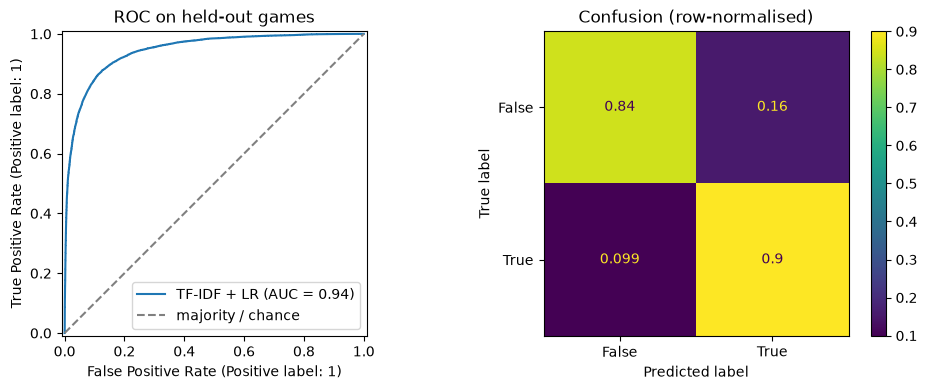

In [3]:
eng = reviews.filter(pl.col("language") == "english")
_, test = sentiment.split_by_game(eng, 0.2, 13)
p = model.predict_proba(test["review_text"].to_list())
y = test["voted_up"].to_numpy()
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
RocCurveDisplay.from_predictions(y, p, ax=ax[0], name="TF-IDF + LR")
ax[0].plot([0, 1], [0, 1], "--", color="grey", label="majority / chance")
ax[0].legend()
ConfusionMatrixDisplay.from_predictions(y, p >= 0.5, ax=ax[1], normalize="true")
ax[0].set_title("ROC on held-out games"); ax[1].set_title("Confusion (row-normalised)")
plt.tight_layout()

In [4]:
# strongest words each way
vec, lr = model.pipeline.named_steps["tfidf"], model.pipeline.named_steps["lr"]
vocab = np.array(vec.get_feature_names_out()); coef = lr.coef_[0]
print("negative:", ", ".join(vocab[np.argsort(coef)[:25]]))
print("positive:", ", ".join(vocab[np.argsort(-coef)[:25]]))

negative: boring, not, not worth, worst, can recommend, unplayable, no, refund, not fun, not recommend, garbage, refunded, worse, don recommend, disappointing, terrible, instead, ruined, unfortunately, trash, thumbs down, at best, crashes, shallow, overrated
positive: great, best, good, amazing, fun, 10 10, excellent, awesome, perfect, cant wait, even better, fantastic, love, so far, solid, not bad, definitely, still recommend, my only, blast, not too, finally, better than, can wait, highly recommend


## Aspect distribution

Share of English reviews mentioning each aspect, split by recommendation. Raw sample shares
(the sample is balanced by rating on purpose, so do not read them as population shares; the
`review_sentiment` tool reweights).

In [5]:
texts = eng["review_text"].to_list()
tags = [aspects_in(t) for t in texts]
rows = [{"aspect": a, "recommended": bool(up), "mentions": a in t}
        for t, up in zip(tags, eng["voted_up"].to_list()) for a in ASPECTS]
dist = (pl.DataFrame(rows).group_by("aspect", "recommended").agg(pl.col("mentions").mean())
        .pivot(on="recommended", index="aspect", values="mentions")
        .rename({"true": "recommended", "false": "not recommended"}).sort("aspect"))
print(f"reviews with at least one aspect: {np.mean([bool(t) for t in tags]):.1%}")
dist

reviews with at least one aspect: 44.2%


aspect,not recommended,recommended
str,f64,f64
"""bugs""",0.201965,0.06377
"""controls""",0.066335,0.030166
"""gameplay""",0.2471,0.172176
"""performance""",0.069798,0.03274
"""price""",0.210261,0.082097
"""story""",0.136005,0.130732


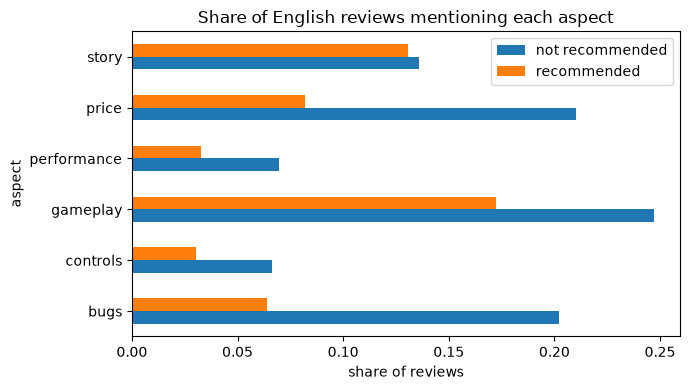

In [6]:
d = dist.to_pandas().set_index("aspect")
d.plot.barh(figsize=(7, 4), title="Share of English reviews mentioning each aspect")
plt.xlabel("share of reviews"); plt.tight_layout()